# Module 10, Part 1: Making models smaller, distillation and pruning

This notebook is the runnable companion to Part 1 of the Module 10 learning content. It tests, with code, two ways of shrinking a trained network and asks the question that matters for deployment: what do you actually get back, in accuracy, parameters and time?

1. **Distillation.** A small student learns from the soft probabilities of a large teacher. We test when this beats training the student on labels alone, what the temperature does, and why the unlabelled data matter.
2. **Unstructured pruning.** Remove the individual weights with the smallest magnitude, with and without fine-tuning, and find where accuracy collapses.
3. **Structured pruning.** Remove whole neurons, which gives a smaller dense network.
4. **Does sparsity make inference faster?** Measure it on this machine, with dense and sparse matrix products.

**Setting.** The 8 by 8 digits data set (1,438 training and 359 test images, 64 pixels each). The teacher is a 64-512-512-10 multilayer perceptron with 301,066 parameters. Everything runs on a CPU, with a fixed seed per experiment, so every number can be reproduced.

In [1]:
import copy, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1)
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_digits_split(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te])

In [3]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(sizes):
    layers = []
    for i in range(len(sizes) - 2):
        layers += [nn.Linear(sizes[i], sizes[i + 1]), nn.ReLU()]
    layers += [nn.Linear(sizes[-2], sizes[-1])]
    return nn.Sequential(*layers)


def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()


def distill_loss(student_logits, teacher_logits, y, T=4.0, alpha=0.7):
    """alpha * T^2 * KL(teacher_T || student_T) + (1 - alpha) * cross entropy with the hard label."""
    soft = F.kl_div(F.log_softmax(student_logits / T, 1), F.softmax(teacher_logits / T, 1), reduction="batchmean") * T * T
    return alpha * soft + (1 - alpha) * F.cross_entropy(student_logits, y)


def train(model, X, y, epochs=60, lr=3e-3, batch=64, seed=0, teacher=None, T=4.0, alpha=0.7, masks=None, wd=0.0):
    """Train with cross entropy, or with the distillation loss when a teacher is given.
    `masks` (a list matching the Linear layers) are re-applied after every step so pruned weights stay zero."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    if teacher is not None:
        teacher.eval()
        with torch.no_grad():
            tl = teacher(X)
    lin = [m for m in model if isinstance(m, nn.Linear)]
    n = len(X)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch):
            b = perm[i:i + batch]
            out = model(X[b])
            loss = distill_loss(out, tl[b], y[b], T, alpha) if teacher is not None else F.cross_entropy(out, y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            if masks is not None:
                with torch.no_grad():
                    for m, mk in zip(lin, masks): m.weight.mul_(mk)
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_nonzero(model):
    return sum((p != 0).sum().item() for p in model.parameters())


def magnitude_masks(model, sparsity, scope="global"):
    """Masks that zero the smallest-magnitude weights. Biases are never pruned."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    if scope == "global":
        allw = torch.cat([m.weight.detach().abs().flatten() for m in lin])
        k = int(sparsity * allw.numel())
        thr = allw.kthvalue(k).values if k > 0 else allw.min() - 1
        return [(m.weight.detach().abs() > thr).float() for m in lin]
    masks = []
    for m in lin:
        w = m.weight.detach().abs().flatten(); k = int(sparsity * w.numel())
        thr = w.kthvalue(k).values if k > 0 else w.min() - 1
        masks.append((m.weight.detach().abs() > thr).float())
    return masks


def apply_masks(model, masks):
    lin = [m for m in model if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for m, mk in zip(lin, masks): m.weight.mul_(mk)


def structured_prune(model, keep):
    """Remove whole hidden neurons (rows of one layer and the matching columns of the next) with the
    smallest L2 norm of incoming weights. Returns a smaller, still dense, network."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    keep_idx = []
    for m in lin[:-1]:
        k = max(1, int(round(keep * m.out_features)))
        keep_idx.append(m.weight.detach().norm(dim=1).topk(k).indices.sort().values)
    sizes = [lin[0].in_features] + [len(i) for i in keep_idx] + [lin[-1].out_features]
    new = mlp(sizes)
    nl = [m for m in new if isinstance(m, nn.Linear)]
    prev = torch.arange(lin[0].in_features)
    for j, (m, n_) in enumerate(zip(lin, nl)):
        rows = keep_idx[j] if j < len(keep_idx) else torch.arange(m.out_features)
        with torch.no_grad():
            n_.weight.copy_(m.weight[rows][:, prev]); n_.bias.copy_(m.bias[rows])
        prev = rows
    return new


# ---------------------------------------------------------------- experiments used by notebook 1 and the learning content
def timeit(fn, repeats=200, warmup=20):
    """Median wall-clock seconds of fn() over `repeats` calls, after a warm-up."""
    import time
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


def exp_distillation(X, y, Xte, yte, seeds=range(5), labelled_fraction=0.05, student_hidden=32, T=4.0):
    """Student of `student_hidden` units, trained four ways, with a 512-512 teacher. Returns per-seed accuracies."""
    out = {k: [] for k in ("teacher_full", "teacher_small", "student_full_hard", "student_full_distilled",
                           "student_small_hard", "student_small_distilled", "student_small_transfer")}
    for seed in seeds:
        torch.manual_seed(seed)
        # full labelled data
        tf = train(mlp([64, 512, 512, 10]), X, y, epochs=60, seed=seed)
        sh = train(mlp([64, student_hidden, 10]), X, y, epochs=60, seed=seed)
        sd = train(mlp([64, student_hidden, 10]), X, y, epochs=60, seed=seed, teacher=tf, T=T, alpha=0.7)
        out["teacher_full"].append(accuracy(tf, Xte, yte)); out["student_full_hard"].append(accuracy(sh, Xte, yte))
        out["student_full_distilled"].append(accuracy(sd, Xte, yte))
        # a small labelled set, the rest unlabelled
        idx = torch.randperm(len(X), generator=torch.Generator().manual_seed(seed))
        n = int(len(X) * labelled_fraction); lab, unl = idx[:n], idx[n:]
        ts = train(mlp([64, 512, 512, 10]), X[lab], y[lab], epochs=60, seed=seed, wd=1e-4)
        s1 = train(mlp([64, student_hidden, 10]), X[lab], y[lab], epochs=100, seed=seed)
        s2 = train(mlp([64, student_hidden, 10]), X[lab], y[lab], epochs=100, seed=seed, teacher=ts, T=T, alpha=0.7)
        Xa = torch.cat([X[lab], X[unl]]); ya = torch.cat([y[lab], torch.zeros(len(unl), dtype=torch.long)])  # y of unlabelled is never used (alpha = 1)
        s3 = train(mlp([64, student_hidden, 10]), Xa, ya, epochs=100, seed=seed, teacher=ts, T=T, alpha=1.0)
        out["teacher_small"].append(accuracy(ts, Xte, yte)); out["student_small_hard"].append(accuracy(s1, Xte, yte))
        out["student_small_distilled"].append(accuracy(s2, Xte, yte)); out["student_small_transfer"].append(accuracy(s3, Xte, yte))
    return out


def exp_temperature(X, y, Xte, yte, temps=(1, 2, 4, 8), seeds=range(5), labelled_fraction=0.05, student_hidden=32):
    """Accuracy of a student distilled on an unlabelled transfer set at several temperatures."""
    res = {t: [] for t in temps}
    for seed in seeds:
        torch.manual_seed(seed)
        idx = torch.randperm(len(X), generator=torch.Generator().manual_seed(seed))
        n = int(len(X) * labelled_fraction); lab, unl = idx[:n], idx[n:]
        ts = train(mlp([64, 512, 512, 10]), X[lab], y[lab], epochs=60, seed=seed, wd=1e-4)
        Xa = torch.cat([X[lab], X[unl]]); ya = torch.zeros(len(Xa), dtype=torch.long)
        for t in temps:
            s = train(mlp([64, student_hidden, 10]), Xa, ya, epochs=100, seed=seed, teacher=ts, T=float(t), alpha=1.0)
            res[t].append(accuracy(s, Xte, yte))
    return res


def exp_pruning(X, y, Xte, yte, sparsities=(0.0, 0.5, 0.8, 0.9, 0.95, 0.98, 0.99), seeds=range(3), finetune_epochs=20):
    """Global magnitude pruning of a 512-512 network, with and without fine-tuning."""
    out = {s: {"no_ft": [], "ft": [], "nonzero": []} for s in sparsities}
    for seed in seeds:
        torch.manual_seed(seed)
        base = train(mlp([64, 512, 512, 10]), X, y, epochs=60, seed=seed)
        for s in sparsities:
            m = copy.deepcopy(base); masks = magnitude_masks(m, s); apply_masks(m, masks)
            out[s]["no_ft"].append(accuracy(m, Xte, yte))
            train(m, X, y, epochs=finetune_epochs, lr=1e-3, seed=seed, masks=masks)
            out[s]["ft"].append(accuracy(m, Xte, yte)); out[s]["nonzero"].append(count_nonzero(m))
    return out


def exp_structured(X, y, Xte, yte, keeps=(1.0, 0.5, 0.25, 0.125, 0.0625), seeds=range(3), finetune_epochs=20):
    """Remove whole hidden neurons, fine-tune, and report accuracy and parameter count."""
    out = {k: {"no_ft": [], "ft": [], "params": None} for k in keeps}
    for seed in seeds:
        torch.manual_seed(seed)
        base = train(mlp([64, 512, 512, 10]), X, y, epochs=60, seed=seed)
        for k in keeps:
            m = structured_prune(base, k)
            out[k]["no_ft"].append(accuracy(m, Xte, yte)); out[k]["params"] = count_params(m)
            train(m, X, y, epochs=finetune_epochs, lr=1e-3, seed=seed)
            out[k]["ft"].append(accuracy(m, Xte, yte))
    return out


def to_sparse_mlp(model):
    """Forward function that uses sparse (CSR) weight matrices, to test whether unstructured sparsity buys speed."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    sp = [m.weight.detach().to_sparse_csr() for m in lin]
    bs = [m.bias.detach() for m in lin]
    def f(x):
        for i, (w, b) in enumerate(zip(sp, bs)):
            x = torch.sparse.mm(w, x.T).T + b
            if i < len(sp) - 1: x = torch.relu(x)
        return x
    return f


def exp_latency(X, y, batch=256, seed=0):
    """Median forward time for one batch of `batch` images, one CPU thread."""
    torch.manual_seed(seed)
    base = train(mlp([64, 512, 512, 10]), X, y, epochs=30, seed=seed)
    xb = X[:batch]
    rows = []
    def bench(name, fn, params, nonzero, acc_model=None):
        with torch.no_grad(): t = timeit(lambda: fn(xb))
        rows.append(dict(name=name, ms=t * 1e3, params=params, nonzero=nonzero))
    with torch.no_grad():
        bench("dense 512-512", base, count_params(base), count_nonzero(base))
        for s in (0.9, 0.98):
            m = copy.deepcopy(base); apply_masks(m, magnitude_masks(m, s))
            bench(f"{int(s * 100)}% unstructured, dense matmul", m, count_params(m), count_nonzero(m))
            bench(f"{int(s * 100)}% unstructured, sparse matmul", to_sparse_mlp(m), count_params(m), count_nonzero(m))
        for k in (0.25, 0.0625):
            m = structured_prune(base, k)
            bench(f"structured, keep {k:g} of the neurons", m, count_params(m), count_nonzero(m))
    return rows

In [4]:
Xtr, ytr, Xte, yte = load_digits_split(0)
print(Xtr.shape, Xte.shape)
base = train(mlp([64, 512, 512, 10]), Xtr, ytr, epochs=60, seed=0)
print("teacher parameters:", count_params(base), " test accuracy:", round(accuracy(base, Xte, yte), 3))

torch.Size([1438, 64]) torch.Size([359, 64])


teacher parameters: 301066  test accuracy: 0.981


## 1. Distillation

A student with one hidden layer of 32 units (2,410 parameters, 125 times smaller than the teacher) is trained in three ways with the same seed:

- **Hard labels only**: ordinary cross entropy on the labelled examples.
- **Distilled on the labelled examples**: a mix of the teacher's softened probabilities and the hard label.
- **Distilled on a transfer set**: the labelled examples *plus all the unlabelled ones*, with the teacher's probabilities as the only target. No label of the unlabelled images is ever used.

We run it in two regimes: all 1,438 images labelled, and only 5% of them labelled (71 images), with the other 1,367 treated as unlabelled. The teacher in the second regime is trained on the 71 labelled images only. Five seeds each.

In [5]:
t0 = time.time()
R = exp_distillation(Xtr, ytr, Xte, yte, seeds=range(5))
names = [("teacher_full", "teacher, all labels"), ("student_full_hard", "student, hard labels"), ("student_full_distilled", "student, distilled"),
         ("teacher_small", "teacher, 5% labels"), ("student_small_hard", "student, hard labels"), ("student_small_distilled", "student, distilled on the 71 labelled"),
         ("student_small_transfer", "student, distilled on the unlabelled transfer set")]
print(f"{'':58s} mean test accuracy   std over 5 seeds")
for k, label in names:
    print(f"{label:58s} {np.mean(R[k]):17.3f} {np.std(R[k]):17.3f}")
print(f"({time.time() - t0:.0f} s)")

                                                           mean test accuracy   std over 5 seeds
teacher, all labels                                                    0.984             0.001
student, hard labels                                                   0.970             0.005
student, distilled                                                     0.968             0.003
teacher, 5% labels                                                     0.855             0.022
student, hard labels                                                   0.823             0.027
student, distilled on the 71 labelled                                  0.759             0.060
student, distilled on the unlabelled transfer set                      0.858             0.020
(43 s)


Three things stand out. With every label available, distillation buys nothing: the student reaches the same accuracy whether or not the teacher helps, because the labels already say everything the teacher knows about this easy task. With only 5% of the labels, the student trained on hard labels is clearly worse than its teacher, and distilling on the same 71 images makes it *worse still*, because the teacher has memorized those 71 images and its soft probabilities on them carry no new information, only confident noise. The student gains when the teacher is allowed to label the unlabelled images: it then matches the teacher's accuracy at a fraction of the size. What distillation transfers is not mainly "softness", it is the teacher's behaviour on inputs the student has no labels for.

### The temperature

A temperature above 1 flattens the teacher's probabilities so that the student sees how the teacher ranks the wrong classes, not only the winner. We distill on the unlabelled transfer set with four temperatures.

temperature   mean test accuracy   std
          1                0.856   0.025
          2                0.860   0.027
          4                0.856   0.028
          8                0.857   0.028


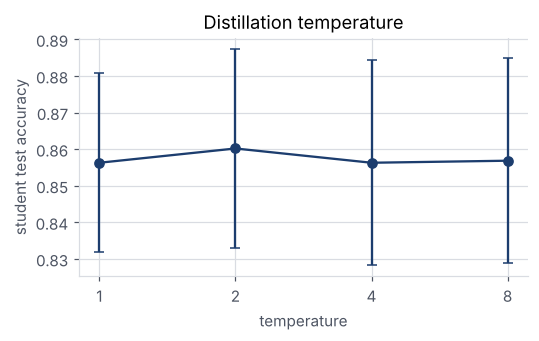

In [6]:
Tm = exp_temperature(Xtr, ytr, Xte, yte, seeds=range(5))
print("temperature   mean test accuracy   std")
for t, v in Tm.items(): print(f"{t:11d} {np.mean(v):20.3f} {np.std(v):7.3f}")
x = list(Tm); m = [np.mean(Tm[t]) for t in x]; s = [np.std(Tm[t]) for t in x]
fig, ax = plt.subplots(figsize=(5, 3.2)); ax.errorbar(range(len(x)), m, s, color=NAVY, marker="o", capsize=3)
ax.set_xticks(range(len(x)), [str(t) for t in x]); ax.set_xlabel("temperature"); ax.set_ylabel("student test accuracy"); ax.set_title("Distillation temperature")
plt.tight_layout(); plt.show()

Here the temperature does **not** matter: the four settings are within one standard deviation of each other. This is an honest negative result and it has an explanation. The teacher is trained on only 71 images, so what limits the student is how many *inputs* the teacher can label for it, not how finely it ranks the wrong classes, and on an easy 10-class task the winner already carries most of the information. Temperature is worth tuning when the classes are many and the wrong ones are informative (similar breeds of dog, neighbouring word senses), not as a reflex.

## 2. Unstructured pruning

We train the 512-512 network, then set the smallest-magnitude weights to zero, ranked across all layers together (global magnitude pruning). We measure accuracy straight after pruning, and again after fine-tuning for 20 epochs with the pruned weights held at zero by a mask.

sparsity   non-zero weights   accuracy, no fine-tuning   accuracy, fine-tuned
    0.00             301066                      0.983                  0.984
    0.50             151050                      0.980                  0.983
    0.80              61041                      0.968                  0.981
    0.90              31038                      0.847                  0.983
    0.95              16036                      0.390                  0.981
    0.98               7035                      0.217                  0.903
    0.99               4035                      0.136                  0.512
(49 s)


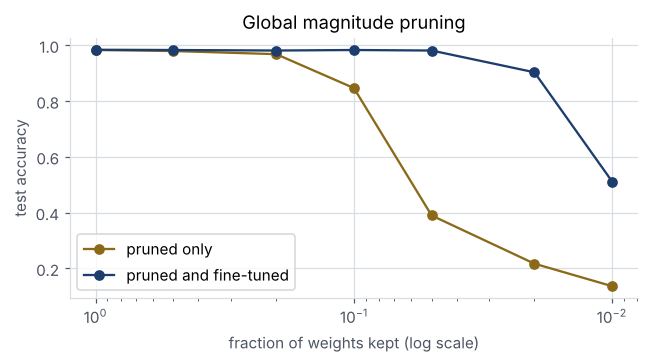

In [7]:
t0 = time.time()
P = exp_pruning(Xtr, ytr, Xte, yte)
print("sparsity   non-zero weights   accuracy, no fine-tuning   accuracy, fine-tuned")
for s, v in P.items():
    print(f"{s:8.2f} {int(np.mean(v['nonzero'])):18d} {np.mean(v['no_ft']):26.3f} {np.mean(v['ft']):22.3f}")
print(f"({time.time() - t0:.0f} s)")
sp = list(P)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot([1 - s for s in sp], [np.mean(P[s]["no_ft"]) for s in sp], color=AMBER, marker="o", label="pruned only")
ax.plot([1 - s for s in sp], [np.mean(P[s]["ft"]) for s in sp], color=NAVY, marker="o", label="pruned and fine-tuned")
ax.set_xscale("log"); ax.invert_xaxis(); ax.set_xlabel("fraction of weights kept (log scale)"); ax.set_ylabel("test accuracy"); ax.legend(); ax.set_title("Global magnitude pruning")
plt.tight_layout(); plt.show()

Without fine-tuning, accuracy holds to 80% sparsity and then falls off a cliff: at 95% it is 0.39. With fine-tuning the network stays at 0.98 up to 95% sparsity, keeping only 16,036 of 301,066 weights, and degrades gradually after that. The fine-tuning step is doing most of the work, not the choice of which weights to remove. The cliff is a property of *this* network and *this* easy task: it is heavily over-parameterized for the digits, which is why so much can go. A network that is already tight, or a harder task, would break earlier.

## 3. Structured pruning

Instead of single weights, remove whole hidden neurons (the ones with the smallest weight norms) and rebuild a smaller *dense* network. Here `keep` is the fraction of neurons kept in each hidden layer.

In [8]:
t0 = time.time()
S = exp_structured(Xtr, ytr, Xte, yte)
print("keep   parameters   accuracy, no fine-tuning   accuracy, fine-tuned")
for k, v in S.items(): print(f"{k:5.4f} {v['params']:12d} {np.mean(v['no_ft']):26.3f} {np.mean(v['ft']):22.3f}")
print(f"({time.time() - t0:.0f} s)")

keep   parameters   accuracy, no fine-tuning   accuracy, fine-tuned
1.0000       301066                      0.983                  0.984
0.5000        85002                      0.963                  0.983
0.2500        26122                      0.878                  0.983
0.1250         8970                      0.612                  0.979
0.0625         3466                      0.344                  0.968
(25 s)


Structured pruning is no worse here than unstructured pruning at a similar size (26,122 parameters give 0.878 before fine-tuning, against 0.847 for 31,038 non-zero weights), and fine-tuning recovers almost everything down to a quarter of the neurons: 0.983. Even at an eighth of the neurons, 8,970 parameters, it reaches 0.979. The real difference is in what comes out: a smaller dense network, not a big network with holes in it.

## 4. Does sparsity make inference faster?

The unstructured networks are the same size as the original: they only have more zeros. A sparse matrix format can skip the zeros, but it costs extra bookkeeping. We time one forward pass of a batch of 256 images on one CPU thread.

In [9]:
rows = exp_latency(Xtr, ytr)
print(f"{'model':46s} {'ms per batch':>13s} {'parameters':>11s} {'non-zero':>9s}")
for r in rows: print(f"{r['name']:46s} {r['ms']:13.3f} {r['params']:11d} {r['nonzero']:9d}")

/tmp/ipykernel_886/1334934256.py:185: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  sp = [m.weight.detach().to_sparse_csr() for m in lin]


model                                           ms per batch  parameters  non-zero
dense 512-512                                          1.386      301066    301066
90% unstructured, dense matmul                         1.427      301066     31038
90% unstructured, sparse matmul                        0.807      301066     31038
98% unstructured, dense matmul                         1.384      301066      7035
98% unstructured, sparse matmul                        0.300      301066      7035
structured, keep 0.25 of the neurons                   0.221       26122     26122
structured, keep 0.0625 of the neurons                 0.068        3466      3466


Run it on your own machine: the exact milliseconds differ, the pattern should not. Unstructured sparsity with an ordinary dense matrix product is **not faster at all**: the hardware still multiplies the zeros, and the time is the same as the dense model to within noise. A sparse matrix format does help on this machine, about 1.5 to 2 times as fast at 90% sparsity and about 4 to 5 times at 98%, but it needs a special format and kernel, and its advantage depends on the library and the hardware. Structured pruning is the fastest by a wide margin, about 7 to 10 times faster with a quarter of the neurons and 25 to 35 times with a sixteenth, because the matrices are simply smaller and any dense kernel runs them. Set that against accuracy: the quarter-size network keeps 0.983, the 98% sparse network only 0.903. This is why a parameter count or a sparsity figure is never a latency claim, and why Lab 10 asks you to measure on your own hardware.

**Try it.** Change `student_hidden` to 8 and then 128 and see where the gain from the transfer set shrinks. Prune layer by layer (`scope="layer"`) instead of globally and compare the cliff. Fine-tune for 5 epochs instead of 20.